In [45]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("data/stroke-dataset.csv")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [46]:
df["stroke"].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [47]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [48]:
df["bmi"] = df["bmi"].fillna(df["bmi"].mean())
df.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [49]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.600000,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.893237,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.500000,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.400000,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.000000,never smoked,1


### Wypełnienie braków w danych

In [50]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["ever_married"] = le.fit_transform(df["ever_married"]) # type: ignore
df["gender"] = le.fit_transform(df["gender"]) # type: ignore
df["Residence_type"] = le.fit_transform(df["gender"]) # type: ignore

df = pd.get_dummies(df, columns=["work_type"], dtype=int)
df = pd.get_dummies(df, columns=["smoking_status"], dtype=int)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              5110 non-null   int64  
 1   gender                          5110 non-null   int64  
 2   age                             5110 non-null   float64
 3   hypertension                    5110 non-null   int64  
 4   heart_disease                   5110 non-null   int64  
 5   ever_married                    5110 non-null   int64  
 6   Residence_type                  5110 non-null   int64  
 7   avg_glucose_level               5110 non-null   float64
 8   bmi                             5110 non-null   float64
 9   stroke                          5110 non-null   int64  
 10  work_type_Govt_job              5110 non-null   int64  
 11  work_type_Never_worked          5110 non-null   int64  
 12  work_type_Private               5110 non-null

### Skalowanie danych MinMax

In [51]:
from sklearn.preprocessing import MinMaxScaler

minmax = MinMaxScaler()
df_minmax = df.copy()
df_minmax[["age", "avg_glucose_level", "bmi"]] = minmax.fit_transform(
    df_minmax[["age", "avg_glucose_level", "bmi"]]
)
df_minmax[["age", "avg_glucose_level", "bmi"]].describe()
df_minmax.head()

,id,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,1,0.816895,0,1,1,1,0.801265,0.301260,1,0,0,1,0,0,0,1,0,0
1,51676,0,0.743652,0,0,1,0,0.679023,0.212981,1,0,0,0,1,0,0,0,1,0
2,31112,1,0.975586,0,1,1,1,0.234512,0.254296,1,0,0,1,0,0,0,0,1,0
3,60182,0,0.597168,0,0,1,0,0.536008,0.276060,1,0,0,1,0,0,0,0,0,1
4,1665,0,0.963379,1,0,1,0,0.549349,0.156930,1,0,0,0,1,0,0,0,1,0


### Skalowanie danych StandardScaler

In [59]:
from sklearn.preprocessing import StandardScaler

COLUMNS = ["age", "avg_glucose_level", "bmi"]

standard = StandardScaler()
df_standard = df.copy()
df_standard[COLUMNS] = standard.fit_transform(
    df_standard[COLUMNS]
)
df_standard[COLUMNS].head()

,age,avg_glucose_level,bmi
0,1.051434,2.706375,1.001234e+00
1,0.786070,2.121559,4.615554e-16
2,1.626390,-0.005028,4.685773e-01
3,0.255342,1.437358,7.154182e-01
4,1.582163,1.501184,-6.357112e-01


### Przedstawienie kwantyli

In [52]:
Q1 = df["bmi"].quantile(0.25)
Q3 = df["bmi"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df["bmi"] < lower) | (df["bmi"] > upper)]
outliers.head()

,id,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
21,13861,0,52.0,1,0,1,0,233.29,48.9,1,0,0,0,1,0,0,0,1,0
66,17004,0,70.0,0,0,1,0,221.58,47.5,1,0,0,1,0,0,0,0,1,0
113,41069,0,45.0,0,0,1,0,224.10,56.6,1,0,0,1,0,0,0,0,1,0
254,32257,0,47.0,0,0,1,0,210.95,50.1,0,0,0,1,0,0,1,0,0,0
258,28674,0,74.0,1,0,1,0,205.84,54.6,0,0,0,0,1,0,0,0,1,0


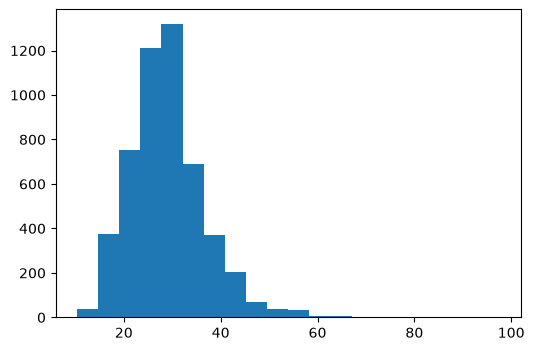

In [53]:
plt.figure(figsize=(6,4))
plt.hist(df["bmi"], bins=20)
plt.show()

### Macierz korelacji

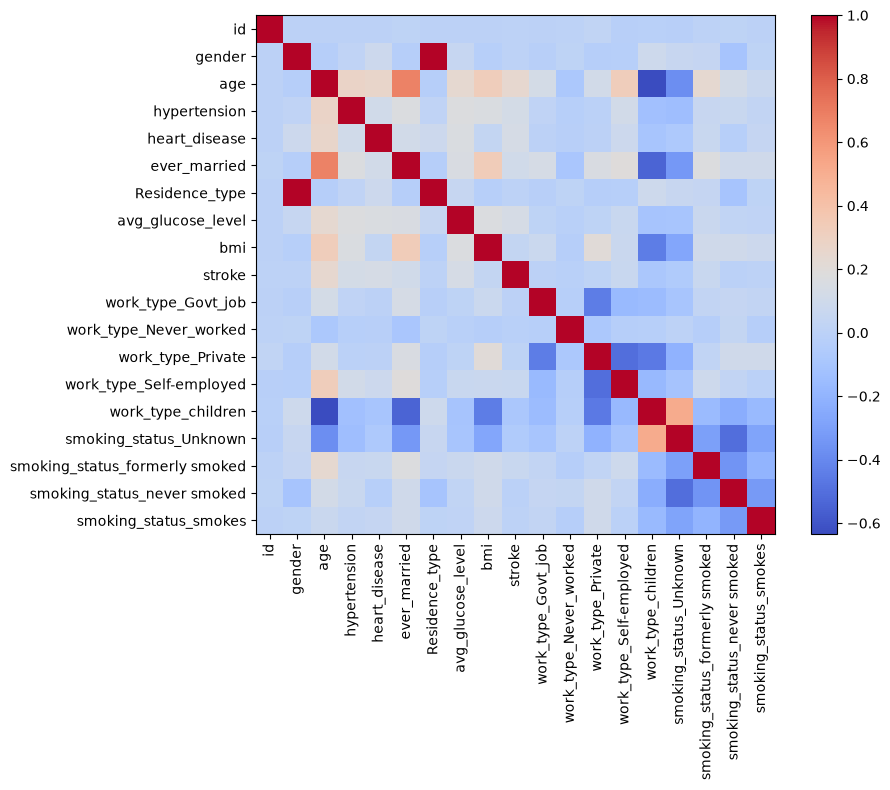

In [54]:
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10,8))
plt.imshow(corr, cmap="coolwarm", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90) # type: ignore
plt.yticks(range(len(corr.columns)), corr.columns) # type: ignore
plt.tight_layout()
plt.show()

### Wybór najlepszych parametrów

In [55]:
X = df.drop(columns=["id", "stroke"])
X = X.select_dtypes(include=[np.number])
y = df["stroke"]

from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=5)
X_selected = selector.fit_transform(X, y)
selected_features = X.columns[selector.get_support()]
selected_features

Index(['age', 'hypertension', 'heart_disease', 'ever_married',
       'avg_glucose_level'],
      dtype='str')

In [56]:
final_df = pd.concat(
    [pd.DataFrame(X_selected, columns=selected_features), y.reset_index(drop=True)],
    axis=1,
)
X = final_df.drop(columns=["stroke"])
y = final_df["stroke"]

In [57]:
X.head()

,age,hypertension,heart_disease,ever_married,avg_glucose_level
0,67.0,0.0,1.0,1.0,228.69
1,61.0,0.0,0.0,1.0,202.21
2,80.0,0.0,1.0,1.0,105.92
3,49.0,0.0,0.0,1.0,171.23
4,79.0,1.0,0.0,1.0,174.12


In [58]:
y.value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64